# MAR20 Class Verification
2 sample images per class (A1-A20) with annotations drawn. Identify each type.

In [1]:
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import defaultdict
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

# Update this path if running on Colab
SRC = Path.home() / '.cache/kagglehub/datasets/khlaifiabilel/military-aircraft-recognition-dataset/versions/1'
xml_dir = SRC / 'Annotations' / 'Horizontal Bounding Boxes'
img_dir = SRC / 'JPEGImages'

# Find 2 images per class where ONLY that class appears
class_images = defaultdict(list)
for xml_path in sorted(xml_dir.glob('*.xml')):
    tree = ET.parse(xml_path)
    root = tree.getroot()
    classes = set()
    for obj in root.findall('object'):
        classes.add(obj.find('name').text)
    if len(classes) == 1:
        cls = list(classes)[0]
        if len(class_images[cls]) < 2:
            class_images[cls].append(xml_path.stem)

print(f'Found samples for {len(class_images)} classes')
for cls in sorted(class_images, key=lambda x: int(x[1:])):
    print(f'  {cls}: images {class_images[cls]}')

Found samples for 20 classes
  A1: images ['1018', '1027']
  A2: images ['10', '1008']
  A3: images ['100', '101']
  A4: images ['1050', '1066']
  A5: images ['1013', '1037']
  A6: images ['1570', '176']
  A7: images ['1024', '103']
  A8: images ['1045', '1067']
  A9: images ['1035', '1049']
  A10: images ['1040', '1063']
  A11: images ['1055', '1060']
  A12: images ['1160', '1427']
  A13: images ['1003', '1014']
  A14: images ['1019', '1031']
  A15: images ['1006', '1026']
  A16: images ['1007', '1025']
  A17: images ['1009', '1028']
  A18: images ['1384', '1684']
  A19: images ['1011', '1017']
  A20: images ['1004', '1023']


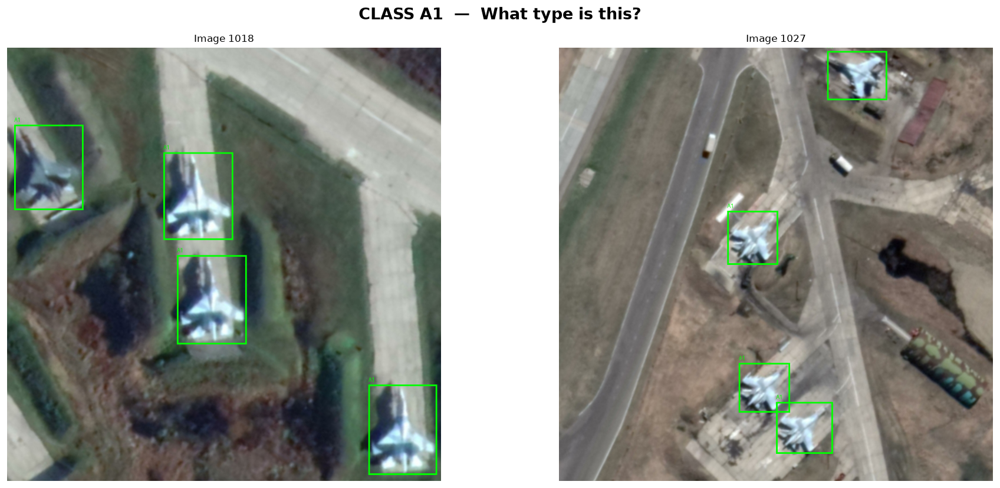

  A1 = ???  (instances in dataset: 3842)



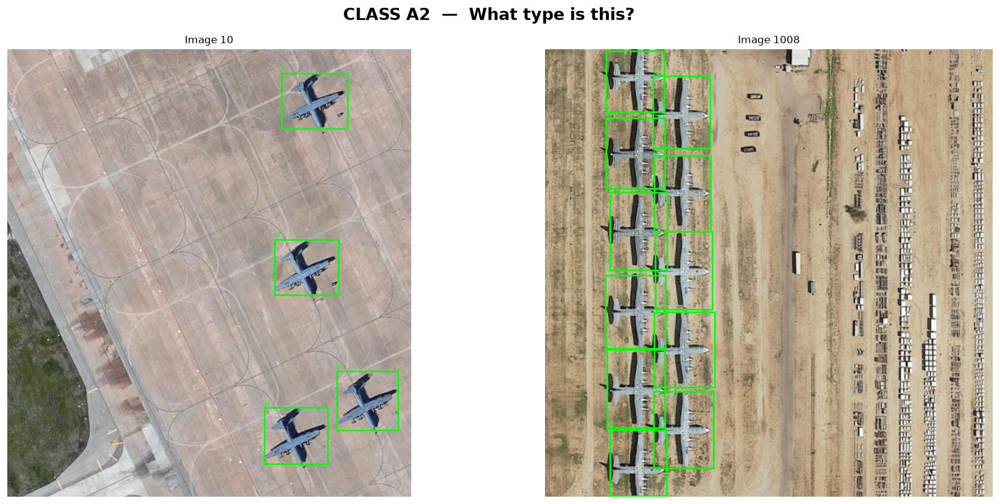

  A2 = ???  (instances in dataset: 3842)



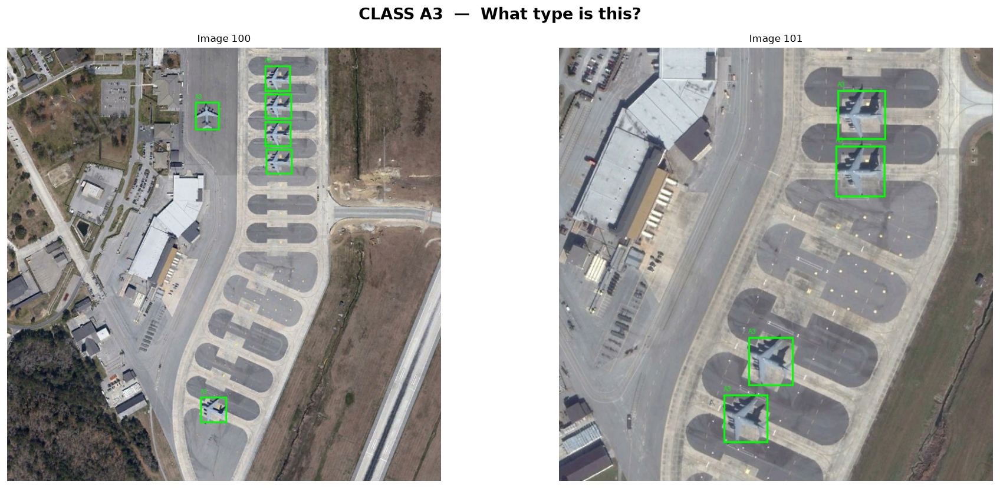

  A3 = ???  (instances in dataset: 3842)



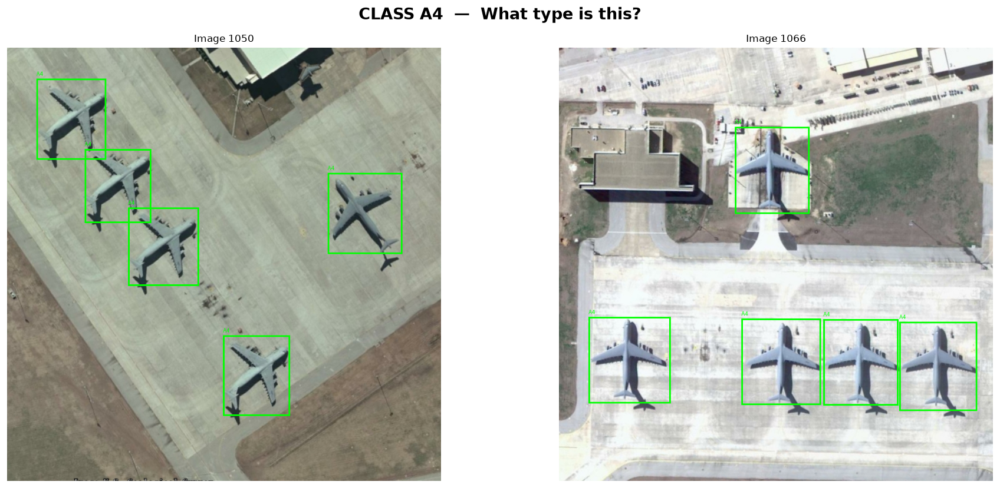

  A4 = ???  (instances in dataset: 3842)



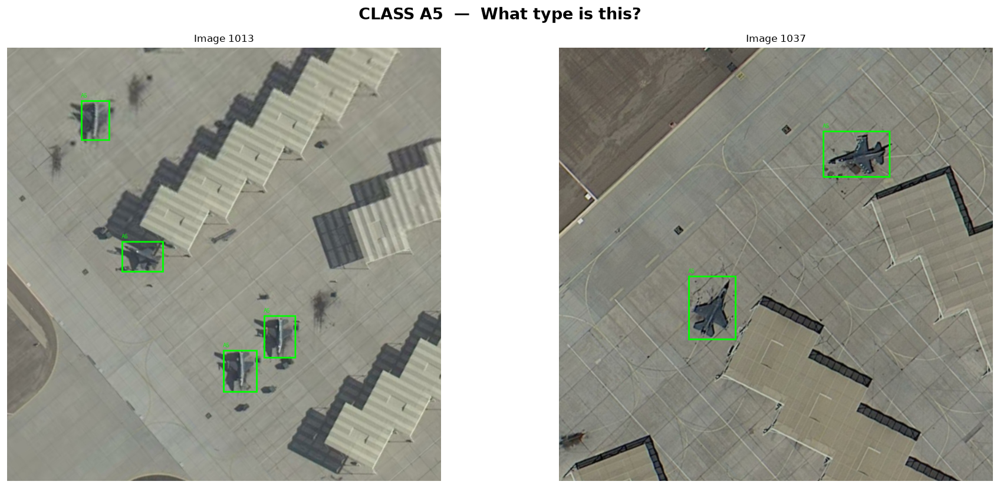

  A5 = ???  (instances in dataset: 3842)



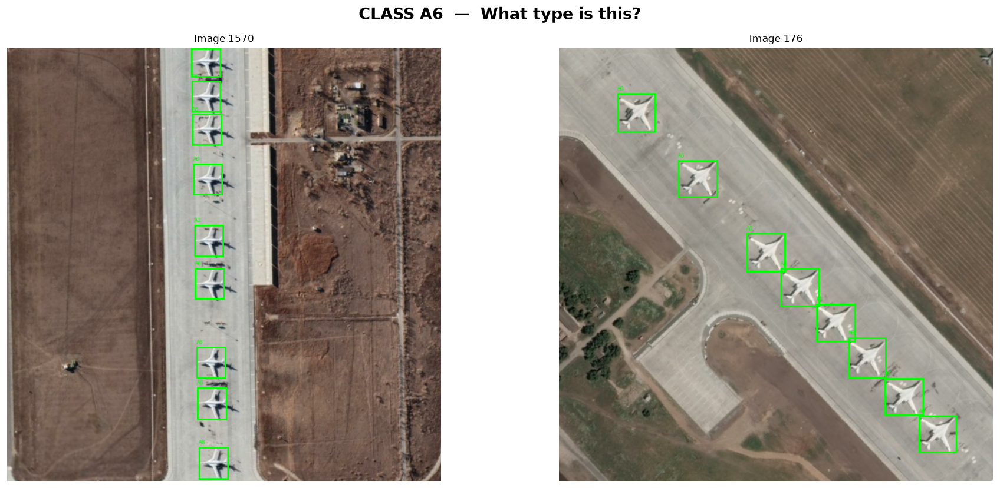

  A6 = ???  (instances in dataset: 3842)



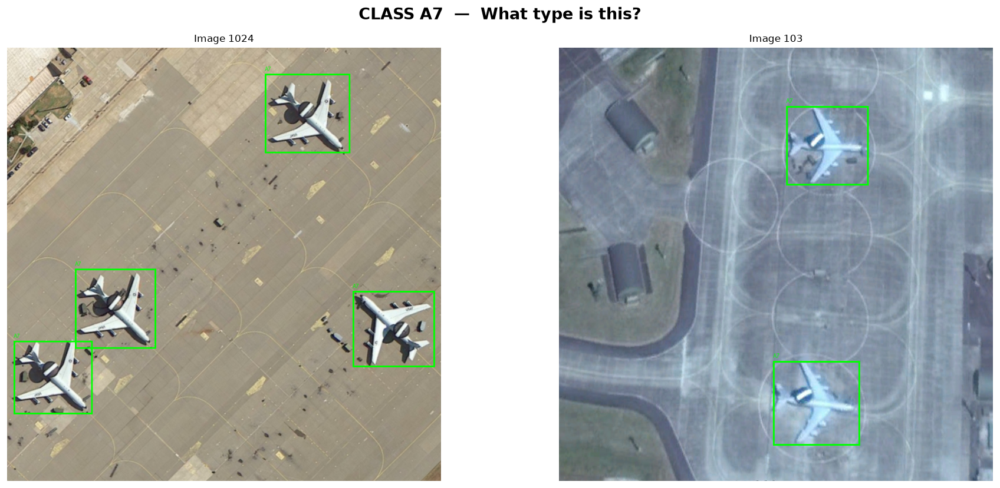

  A7 = ???  (instances in dataset: 3842)



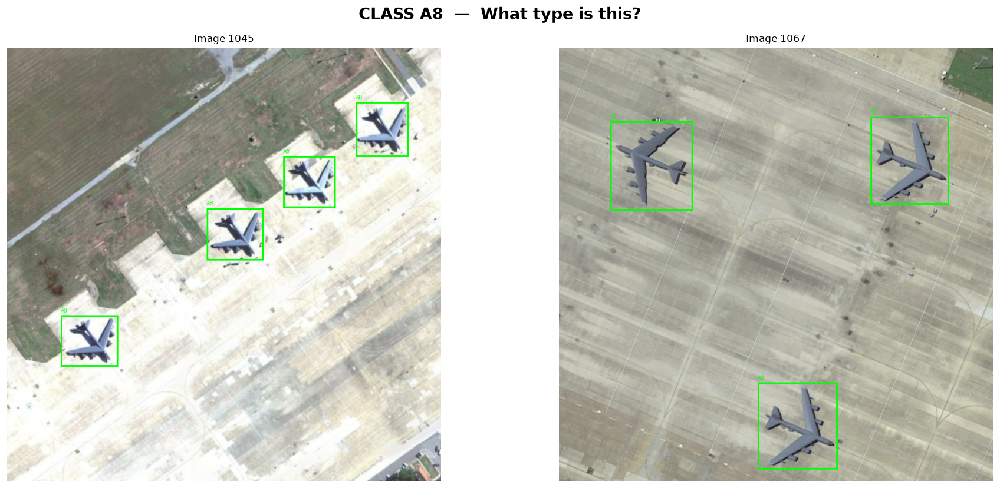

  A8 = ???  (instances in dataset: 3842)



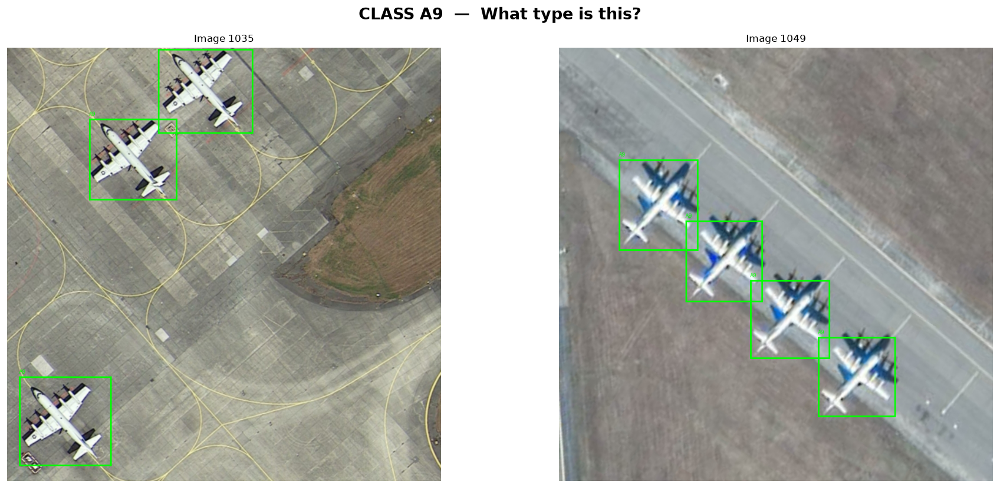

  A9 = ???  (instances in dataset: 3842)



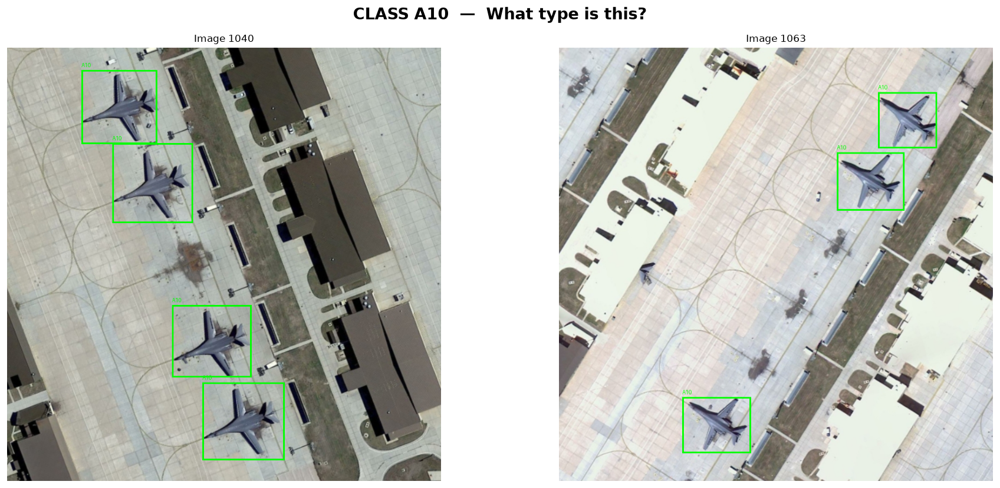

  A10 = ???  (instances in dataset: 3842)



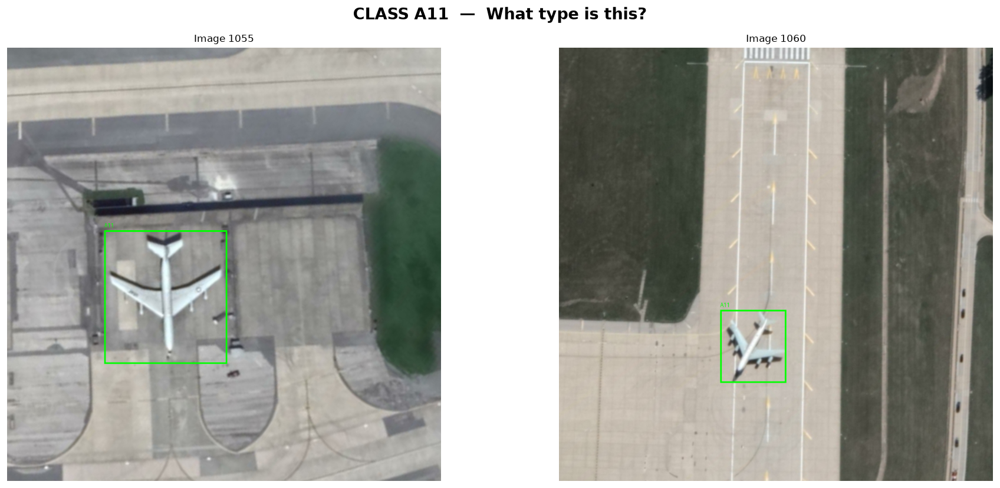

  A11 = ???  (instances in dataset: 3842)



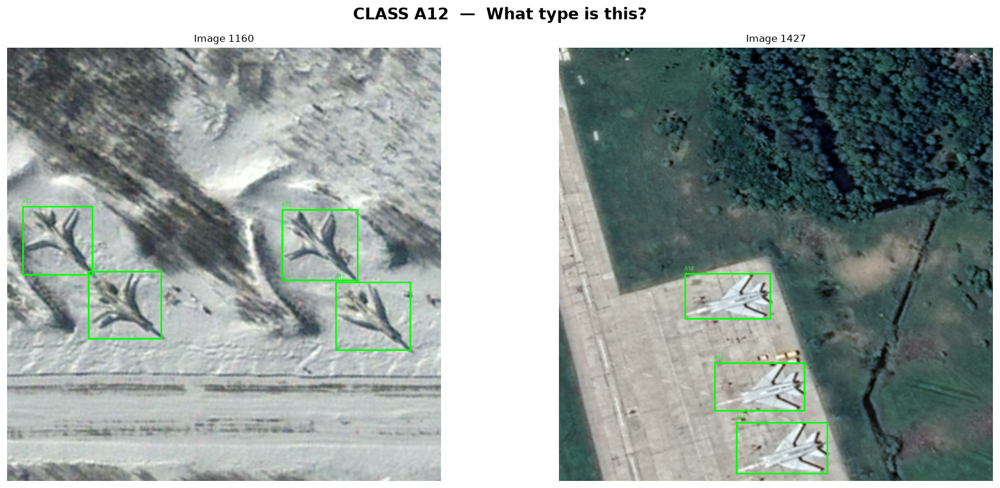

  A12 = ???  (instances in dataset: 3842)



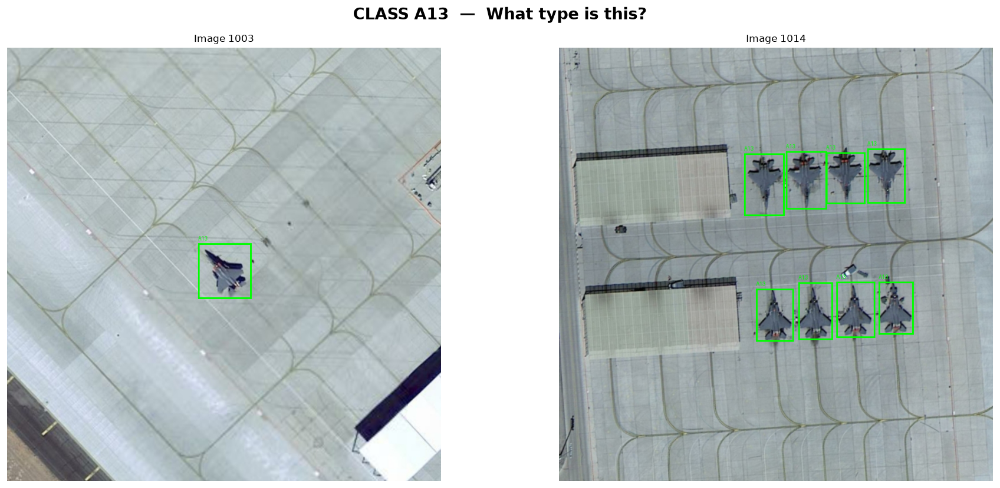

  A13 = ???  (instances in dataset: 3842)



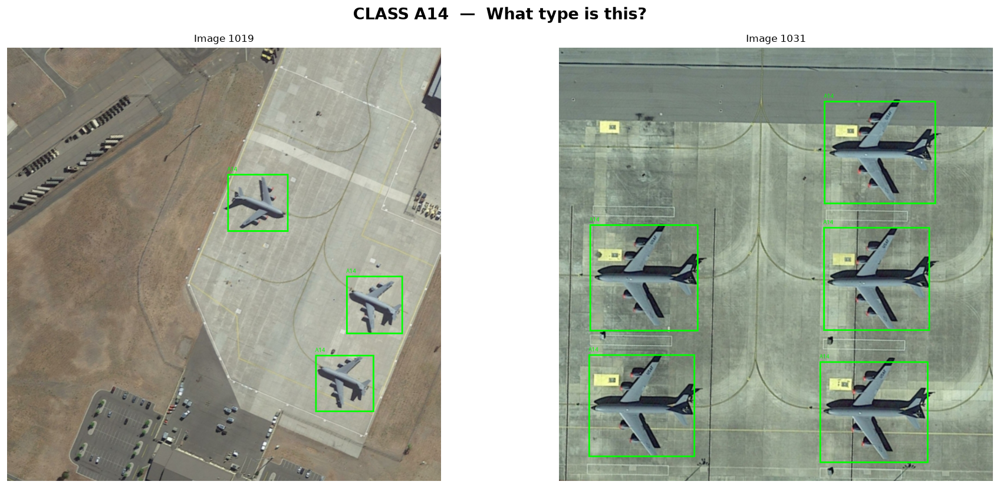

  A14 = ???  (instances in dataset: 3842)



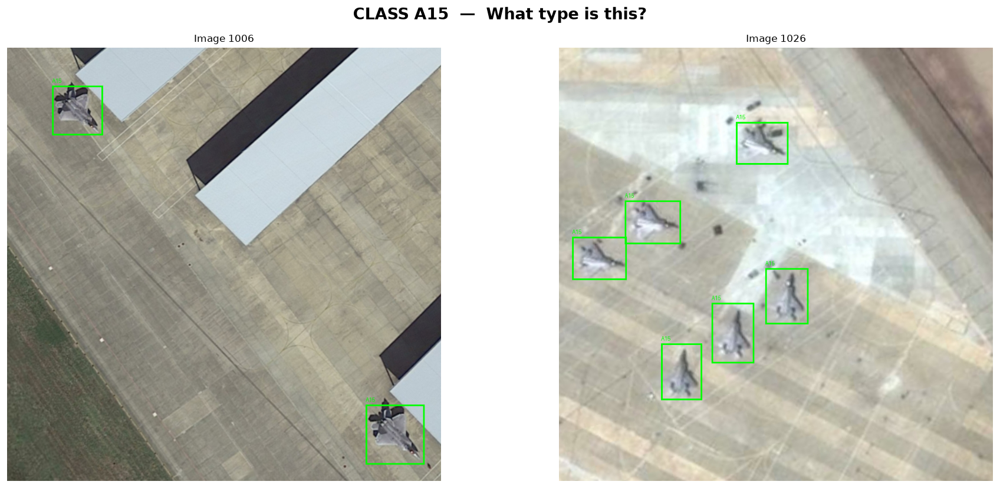

  A15 = ???  (instances in dataset: 3842)



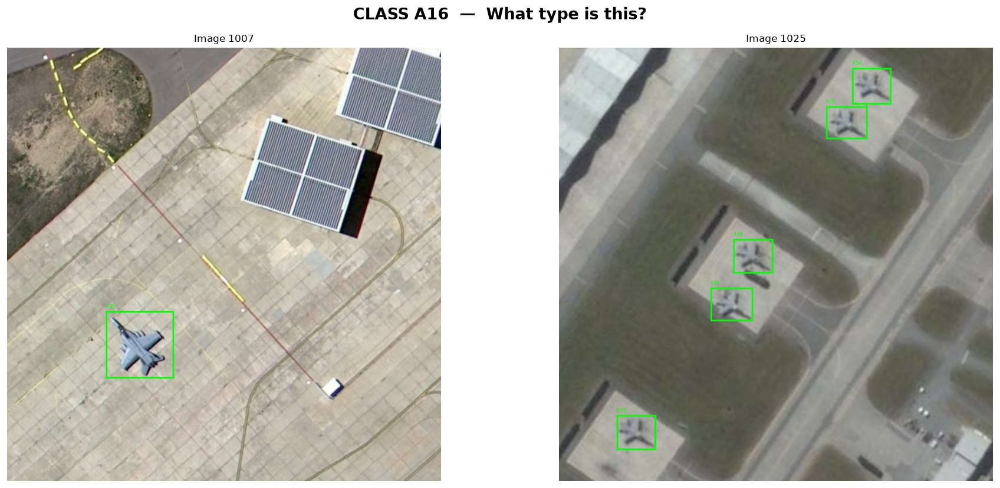

  A16 = ???  (instances in dataset: 3842)



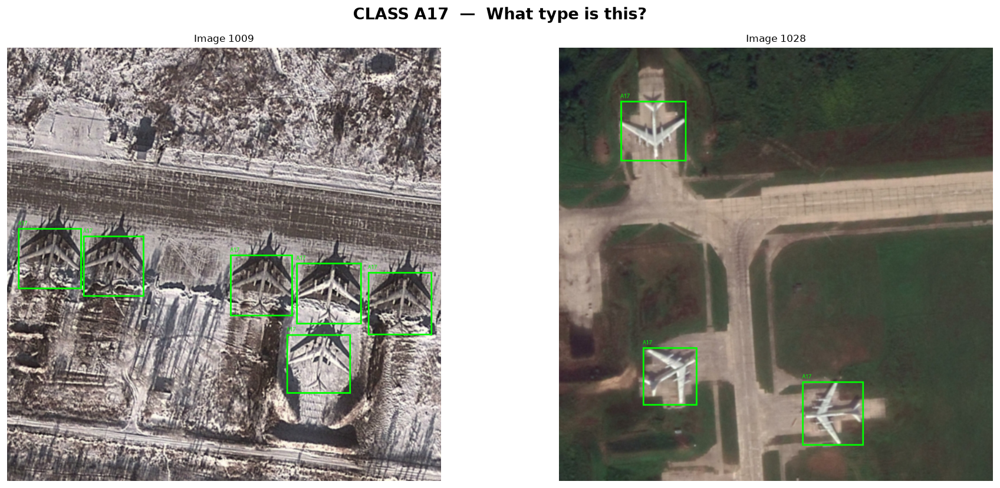

  A17 = ???  (instances in dataset: 3842)



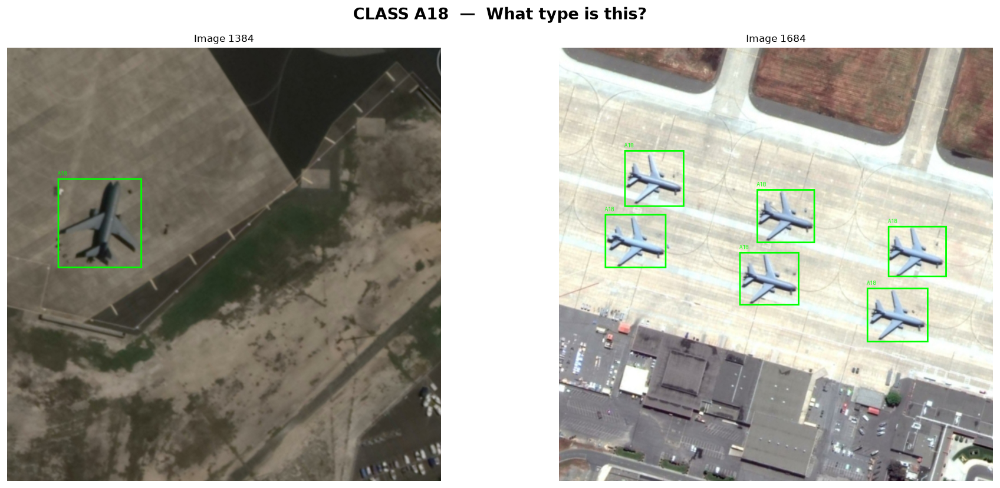

  A18 = ???  (instances in dataset: 3842)



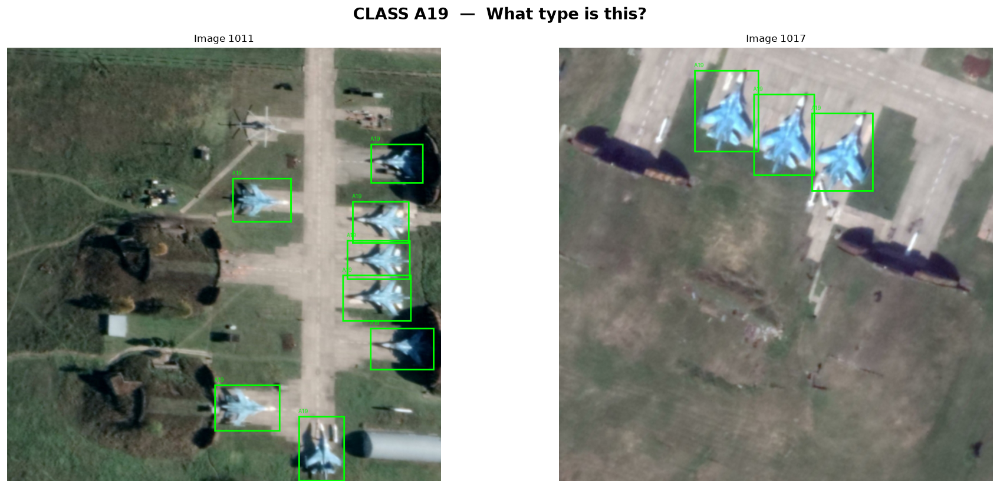

  A19 = ???  (instances in dataset: 3842)



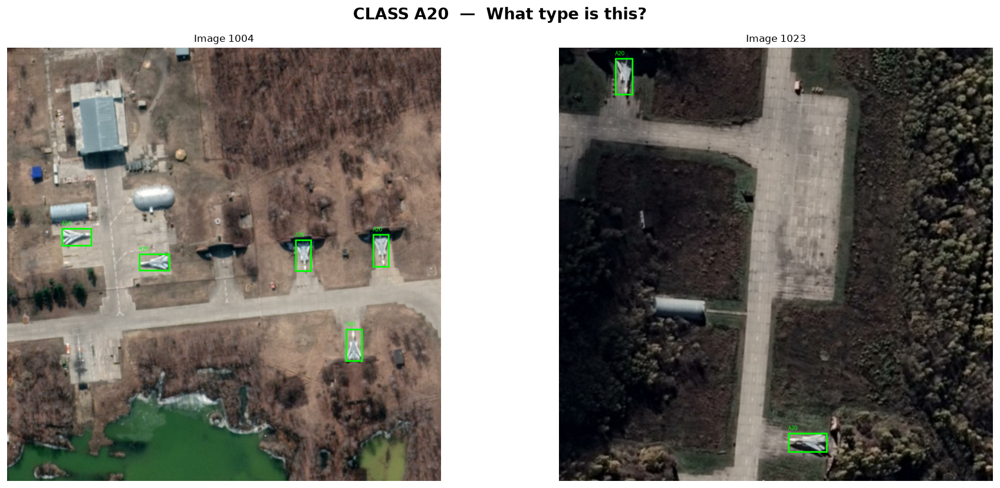

  A20 = ???  (instances in dataset: 3842)



In [2]:
def draw_annotations(img_id):
    """Load image and draw bounding boxes with class labels."""
    img = Image.open(img_dir / f'{img_id}.jpg')
    xml_path = xml_dir / f'{img_id}.xml'
    tree = ET.parse(xml_path)
    root = tree.getroot()
    draw = ImageDraw.Draw(img)
    
    for obj in root.findall('object'):
        name = obj.find('name').text
        bbox = obj.find('bndbox')
        x1 = int(bbox.find('xmin').text)
        y1 = int(bbox.find('ymin').text)
        x2 = int(bbox.find('xmax').text)
        y2 = int(bbox.find('ymax').text)
        draw.rectangle([x1, y1, x2, y2], outline='lime', width=3)
        draw.text((x1, y1 - 15), name, fill='lime')
    
    return img

# Display 2 images per class
sorted_classes = sorted(class_images.keys(), key=lambda x: int(x[1:]))

for cls in sorted_classes:
    imgs = class_images[cls]
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    fig.suptitle(f'CLASS {cls}  —  What type is this?', fontsize=16, fontweight='bold')
    
    for i, img_id in enumerate(imgs):
        annotated = draw_annotations(img_id)
        axes[i].imshow(annotated)
        axes[i].set_title(f'Image {img_id}', fontsize=10)
        axes[i].axis('off')
    
    # If only 1 image found
    if len(imgs) < 2:
        axes[1].axis('off')
        axes[1].text(0.5, 0.5, 'No second sample', ha='center', va='center', fontsize=12, color='gray')
    
    plt.tight_layout()
    plt.show()
    print(f'  {cls} = ???  (instances in dataset: {sum(1 for _ in xml_dir.glob("*.xml"))})')
    print()

## Fill in the mapping below after reviewing

```python
CLASS_MAP = {
    'A1': '???',
    'A2': '???',
    'A3': '???',
    'A4': '???',
    'A5': '???',
    'A6': '???',
    'A7': '???',
    'A8': '???',
    'A9': '???',
    'A10': '???',
    'A11': '???',
    'A12': '???',
    'A13': '???',
    'A14': '???',
    'A15': '???',
    'A16': '???',
    'A17': '???',
    'A18': '???',
    'A19': '???',
    'A20': '???',
}
```